# 20 — Generalized Advantage Estimation
GAE는 행동 선택이나 학습 알고리즘이 아니라 Return/Advantage 추정기다.
$\delta_t=r_t+\gamma(1-terminated_t)V(s_{t+1})-V(s_t)$,
$A_t=\delta_t+\gamma\lambda(1-(terminated_t\lor truncated_t))A_{t+1}$, $R_t=A_t+V(s_t)$.
마지막 이후의 Advantage는 0이다. 자연 종료는 Bootstrap을 제거하고, Time-limit은 Final V로 Bootstrap하면서 Trace만 끊는다. 두 flag가 True면 자연 종료가 우선이다.

[GAE 원 논문](https://arxiv.org/abs/1506.02438). 아래에서는 라이브러리의 계산기를 호출하며 수식을 재구현하지 않는다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
from gymnasium.vector import AsyncVectorEnv, AutoresetMode
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from modular_rl import Model, representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.environment import validate_vector_env, final_observations
from notebooks.gymnasium.tutorial_utils import evaluate, history, record


FAST=os.environ.get('MODULARRL_FAST','0')=='1'
SEED,GAMMA,N_ENVS,HORIZON=7,.9,4,8
torch.manual_seed(SEED);torch.set_num_threads(1);plt.close('all')
model=Model(R.MLP(4,(16,),activation=nn.Tanh),
            E.ActorCritic(E.CategoricalPolicy(16,2),E.StateValue(16)),S.Categorical())
model.eval()
buffer=B.Rollout(HORIZON,N_ENVS)

Matplotlib is building the font cache; this may take a moment.


## 실제 시간순 Rollout
일부러 TimeLimit=3을 사용해 Rollout 안에 여러 Episode를 포함한다. Gymnasium >=1.1 SAME_STEP의 Reset 관측과 Final 관측을 분리한다. 평가 모드에서 고정된 Model로 수집하므로 정상 진행의 next_value[t]는 value[t+1]과 일치한다. 이것이 lambda=1과 RolloutReturn 동등성의 전제다.

In [2]:
env=AsyncVectorEnv([lambda:gym.make('CartPole-v1',max_episode_steps=3) for _ in range(N_ENVS)],
                   context='spawn',copy=True,autoreset_mode=AutoresetMode.SAME_STEP)
try:
    validate_vector_env(env)
    observation,_=env.reset(seed=[SEED+i for i in range(N_ENVS)])
    for _ in range(HORIZON):
        with torch.no_grad():
            estimate=model(observation)
            selected=model.action_selector.select(estimate)
        returned,reward,terminated,truncated,info=env.step(selected.action.cpu().numpy())
        actual_next=final_observations(returned,terminated,truncated,info)
        buffer.add(observation,selected.action,reward,actual_next,terminated,truncated,
                   value=estimate.values.v,log_prob=selected.log_prob)
        observation=returned
    rollout=buffer.get().to(dtype=torch.float32)
finally:
    env.close()
with torch.no_grad():
    next_value=model(rollout.next_observation.flatten(0,1)).values.v.reshape(HORIZON,N_ENVS)
    gae_results={lam:T.GAE(GAMMA,lam).generate(rollout.reward,rollout.value,next_value,
                                        rollout.terminated,rollout.truncated) for lam in (0.,.5,.95,1.)}
    returns=T.RolloutReturn(GAMMA).generate(rollout.reward,next_value,rollout.terminated,rollout.truncated)
    td0=T.TD0(GAMMA).generate(rollout.reward,next_value,rollout.terminated)-rollout.value
    torch.testing.assert_close(gae_results[0.].advantage,td0)
    torch.testing.assert_close(gae_results[1.].returns,returns)
advantages=gae_results[.95].advantage
print('truncation locations',rollout.truncated.nonzero().tolist())
print('actual final observations',rollout.next_observation[rollout.truncated])
print('GAE(.95) advantage',advantages)
print('GAE(.95) returns',gae_results[.95].returns)
print('lambda=1 versus RolloutReturn max error',float((gae_results[1.].returns-returns).abs().max()))

truncation locations [[2, 0], [2, 1], [2, 2], [2, 3], [5, 0], [5, 1], [5, 2], [5, 3]]
actual final observations tensor([[ 0.0266,  0.2338,  0.0089, -0.2962],
        [-0.0105,  0.2447, -0.0226, -0.2822],
        [ 0.0318, -0.2170,  0.0180,  0.3325],
        [ 0.0555,  0.1646,  0.0138, -0.2989],
        [-0.0216, -0.1557, -0.0426,  0.2800],
        [ 0.0402, -0.2056, -0.0129,  0.2720],
        [ 0.0202,  0.2350,  0.0451, -0.2137],
        [ 0.0108,  0.1580,  0.0038, -0.2417]])
GAE(.95) advantage tensor([[2.6172, 2.6157, 2.5922, 2.6225],
        [1.8602, 1.8594, 1.8761, 1.8638],
        [0.9826, 1.0259, 0.9880, 0.9836],
        [2.5875, 2.5920, 2.6172, 2.6213],
        [1.8726, 1.8290, 1.9082, 1.8630],
        [0.9864, 0.9882, 1.0268, 0.9829],
        [1.9015, 1.8680, 1.8998, 1.8333],
        [1.0217, 0.9837, 1.0206, 0.9915]])
GAE(.95) returns tensor([[2.5557, 2.5544, 2.5154, 2.5429],
        [1.8216, 1.8201, 1.7776, 1.8075],
        [0.9620, 0.9625, 0.9134, 0.9464],
        [2.5183, 2.5

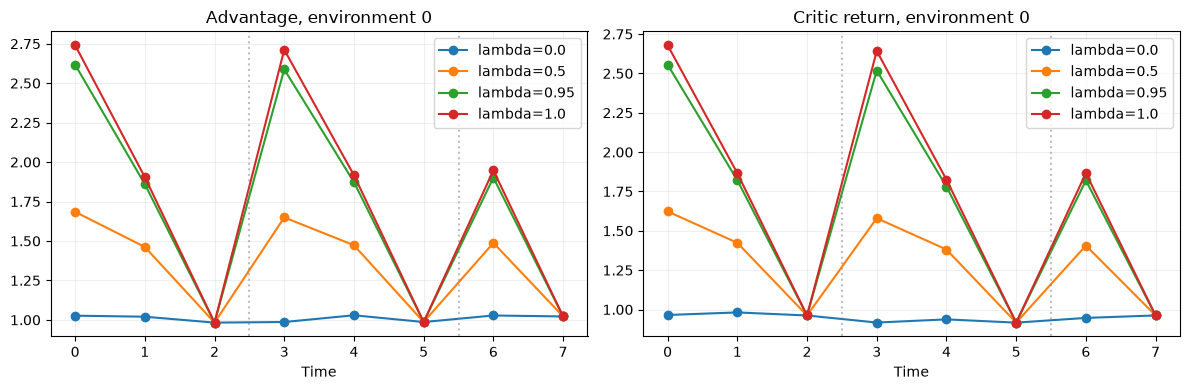

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for lam,result in gae_results.items():
    axes[0].plot(result.advantage[:,0],marker='o',label=f'lambda={lam}')
    axes[1].plot(result.returns[:,0],marker='o',label=f'lambda={lam}')
for index in rollout.truncated[:,0].nonzero().flatten().tolist():
    for ax in axes:ax.axvline(index+.5,color='gray',linestyle=':',alpha=.5)
axes[0].set_title('Advantage, environment 0');axes[1].set_title('Critic return, environment 0')
for ax in axes:ax.set_xlabel('Time');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();plt.show()

## A2C에서도 재사용
T.RolloutReturn 경로는 기존과 같다. T.GAE를 전달하면 Actor에는 고정 GAE Advantage, Critic에는 GAE Return을 사용한다. Generator 자체는 Gradient를 보존하며 Learner가 no_grad 경계를 관리한다. 아래 학습은 동일 fresh Rollout에서 단 한 번 수행한다.

In [4]:
learner=L.A2C(model,torch.optim.Adam(model.parameters(),lr=.001),T.GAE(GAMMA,.95),U.ActorCritic())
result=learner.learn(rollout)
summary=dict(time=HORIZON,n_envs=N_ENVS,truncated=int(rollout.truncated.sum()),
             actor_loss=result.actor_loss.item(),critic_loss=result.critic_loss.item())
print(summary)

{'time': 8, 'n_envs': 4, 'truncated': 8, 'actor_loss': 1.2274705171585083, 'critic_loss': 1.6928318738937378}
